# 02 · Dentro del sujeto vs. entre sujetos

**Pregunta (H1):** ¿cuánto desempeño pierde un clasificador de imaginería motora cuando se lo usa con una persona que no vio al entrenar?

Se evalúa **el mismo clasificador** de dos formas:

- **Dentro del sujeto:** para cada sujeto, validación cruzada estratificada de 5 pliegues repetida 10 veces con sus propios ensayos. Es el escenario optimista (la BCI calibrada a medida).
- **Entre sujetos (leave-subject-out):** se entrena con 105 sujetos y se evalúa con el que quedó afuera, 106 veces. Es el escenario de un usuario nuevo sin calibrar.

Como cada sujeto tiene un valor en cada esquema, la comparación es **pareada**.

**Configuración base** (la etapa 4 la varía):

| Paso | Elección | Por qué |
|---|---|---|
| Referencia | Promedio común (CAR) | Reduce el ruido compartido por todos los electrodos |
| Filtro | 8–30 Hz | Cubre mu (8–12 Hz) y beta (13–30 Hz), donde aparece el ERD |
| Ventana | 0,5 a 2,5 s desde la consigna | En el notebook 01 la diferencia entre clases se concentró entre 0,5 y 1,5 s |
| Características | CSP, 6 componentes, log-varianza | Filtros espaciales que maximizan la diferencia de potencia entre clases |
| Clasificador | LDA | Estándar en BCI de imaginería motora; rápido y con poca varianza |
| Métricas | Balanced accuracy y AUC | La consigna pide no usar accuracy sola |


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

from bci.pipelines import (PREPROC_BASE, cargar_dataset, crear_pipeline,
                           evaluar_entre, evaluar_intra, umbral_azar)

RESULTADOS = Path("..") / "resultados"
RESULTADOS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"


In [2]:
X, y, grupos = cargar_dataset(**PREPROC_BASE)
n_por_sujeto = pd.Series(grupos).value_counts()
print(f"{X.shape[0]} ensayos, {X.shape[1]} canales, {X.shape[2]} muestras ({X.shape[2] / 160:.1f} s a 160 Hz)")
print(f"{len(n_por_sujeto)} sujetos, entre {n_por_sujeto.min()} y {n_por_sujeto.max()} ensayos cada uno")
print(f"Proporción de 'derecha': {y.mean():.3f}")


4768 ensayos, 64 canales, 321 muestras (2.0 s a 160 Hz)
106 sujetos, entre 43 y 45 ensayos cada uno
Proporción de 'derecha': 0.495


## Dentro del sujeto

In [3]:
pipe = crear_pipeline("csp_lda")
intra = evaluar_intra(pipe, X, y, grupos, n_splits=5, n_repeats=10, semilla=0)
intra.to_csv(RESULTADOS / "02_intra_sujeto.csv", index=False)
intra.describe().round(3)


,sujeto,n_ensayos,balanced_accuracy,auc
count,106.000,106.000,106.000,106.000
mean,53.915,44.981,0.604,0.633
std,31.366,0.194,0.142,0.176
min,1.000,43.000,0.359,0.277
25%,27.250,45.000,0.505,0.501
50%,53.500,45.000,0.551,0.574
75%,79.750,45.000,0.698,0.775
max,109.000,45.000,1.000,1.000


## Entre sujetos (leave-subject-out)

In [4]:
entre = evaluar_entre(pipe, X, y, grupos)
entre.to_csv(RESULTADOS / "02_entre_sujetos.csv", index=False)
entre.describe().round(3)


,sujeto,n_ensayos,balanced_accuracy,auc
count,106.000,106.000,106.000,106.000
mean,53.915,44.981,0.623,0.709
std,31.366,0.194,0.134,0.163
min,1.000,43.000,0.371,0.300
25%,27.250,45.000,0.522,0.584
50%,53.500,45.000,0.585,0.684
75%,79.750,45.000,0.739,0.857
max,109.000,45.000,0.978,1.000


## Comparación pareada

Para cada sujeto se calcula también el **umbral de azar**: la balanced accuracy mínima para decir que el clasificador supera al azar con p < 0,05 (prueba binomial unilateral con su cantidad de ensayos). Con 45 ensayos el umbral es 0,644, lejos del 0,5 que se suele tomar como referencia.

In [5]:
comp = intra.merge(entre, on=["sujeto", "n_ensayos"], suffixes=("_intra", "_entre"))
comp["umbral_azar"] = comp["n_ensayos"].map(umbral_azar)
comp["perdida"] = comp["balanced_accuracy_intra"] - comp["balanced_accuracy_entre"]
comp.to_csv(RESULTADOS / "02_comparacion.csv", index=False)

def resumen(col):
    v = comp[col]
    return {"media": v.mean(), "desvío": v.std(), "mediana": v.median(),
            "p25": v.quantile(.25), "p75": v.quantile(.75)}

tabla = pd.DataFrame({
    "BA dentro": resumen("balanced_accuracy_intra"),
    "BA entre": resumen("balanced_accuracy_entre"),
    "AUC dentro": resumen("auc_intra"),
    "AUC entre": resumen("auc_entre"),
    "Pérdida (BA)": resumen("perdida"),
}).T.round(3)
tabla


,media,desvío,mediana,p25,p75
BA dentro,0.604,0.142,0.551,0.505,0.698
BA entre,0.623,0.134,0.585,0.522,0.739
AUC dentro,0.633,0.176,0.574,0.501,0.775
AUC entre,0.709,0.163,0.684,0.584,0.857
Pérdida (BA),-0.019,0.102,-0.024,-0.073,0.056


In [6]:
w_ba = wilcoxon(comp["balanced_accuracy_intra"], comp["balanced_accuracy_entre"])
w_auc = wilcoxon(comp["auc_intra"], comp["auc_entre"])
sobre_azar_intra = (comp["balanced_accuracy_intra"] >= comp["umbral_azar"]).sum()
sobre_azar_entre = (comp["balanced_accuracy_entre"] >= comp["umbral_azar"]).sum()
pierden = (comp["perdida"] > 0).sum()

print(f"Wilcoxon pareado, balanced accuracy: W = {w_ba.statistic:.0f}, p = {w_ba.pvalue:.2g}")
print(f"Wilcoxon pareado, AUC:               W = {w_auc.statistic:.0f}, p = {w_auc.pvalue:.2g}")
print(f"Sujetos que pierden desempeño al pasar a entre sujetos: {pierden} de {len(comp)}")
print(f"Sujetos sobre el umbral de azar: dentro {sobre_azar_intra}, entre {sobre_azar_entre} (de {len(comp)})")
print(f"Correlación entre ambos esquemas (Spearman): {comp['balanced_accuracy_intra'].corr(comp['balanced_accuracy_entre'], method='spearman'):.2f}")


Wilcoxon pareado, balanced accuracy: W = 2259, p = 0.069
Wilcoxon pareado, AUC:               W = 941, p = 3.9e-09
Sujetos que pierden desempeño al pasar a entre sujetos: 43 de 106
Sujetos sobre el umbral de azar: dentro 32, entre 37 (de 106)
Correlación entre ambos esquemas (Spearman): 0.64


## Figura 1 · Cada sujeto en los dos esquemas

Cada punto es un sujeto. Los que quedan **debajo de la diagonal** rinden peor con el modelo entre sujetos que con el suyo propio. Las líneas punteadas marcan el umbral de azar para 45 ensayos.

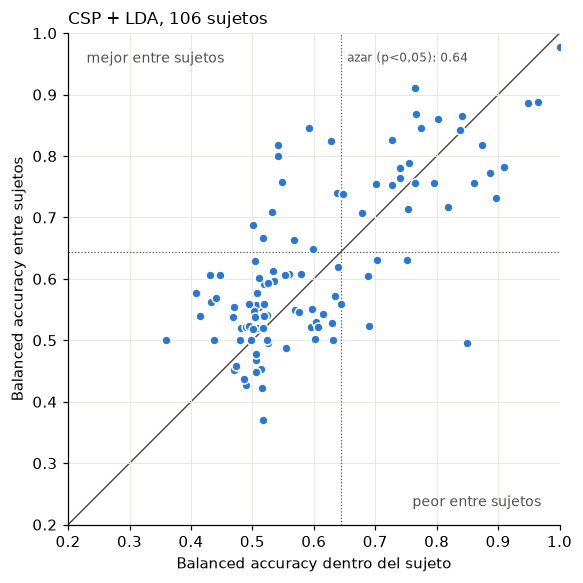

In [7]:
ua = umbral_azar(45)
fig, ax = plt.subplots(figsize=(5.6, 5.4))
ax.plot([0.2, 1], [0.2, 1], color=GRIS, lw=1, zorder=1)
ax.axvline(ua, color=GRIS, lw=0.8, ls=":")
ax.axhline(ua, color=GRIS, lw=0.8, ls=":")
ax.scatter(comp["balanced_accuracy_intra"], comp["balanced_accuracy_entre"], s=34,
           color=AZUL, edgecolor="white", linewidth=1, zorder=2)
ax.set_xlim(0.2, 1); ax.set_ylim(0.2, 1); ax.set_aspect("equal")
ax.set_xlabel("Balanced accuracy dentro del sujeto")
ax.set_ylabel("Balanced accuracy entre sujetos")
ax.set_title("CSP + LDA, 106 sujetos", loc="left", fontsize=11)
ax.text(0.97, 0.23, "peor entre sujetos", ha="right", color=GRIS, fontsize=9)
ax.text(0.23, 0.97, "mejor entre sujetos", va="top", color=GRIS, fontsize=9)
ax.text(ua + 0.01, 0.97, f"azar (p<0,05): {ua:.2f}", color=GRIS, fontsize=8, va="top")
fig.tight_layout()
fig.savefig(RESULTADOS / "02_intra_vs_entre.png", dpi=200)


## Figura 2 · Pérdida por sujeto

Diferencia de balanced accuracy (dentro − entre) de cada sujeto, ordenados de mayor a menor. Las barras hacia arriba son sujetos que pierden al usar el modelo de otros; hacia abajo, sujetos a los que el modelo de otros les funciona mejor que el propio.

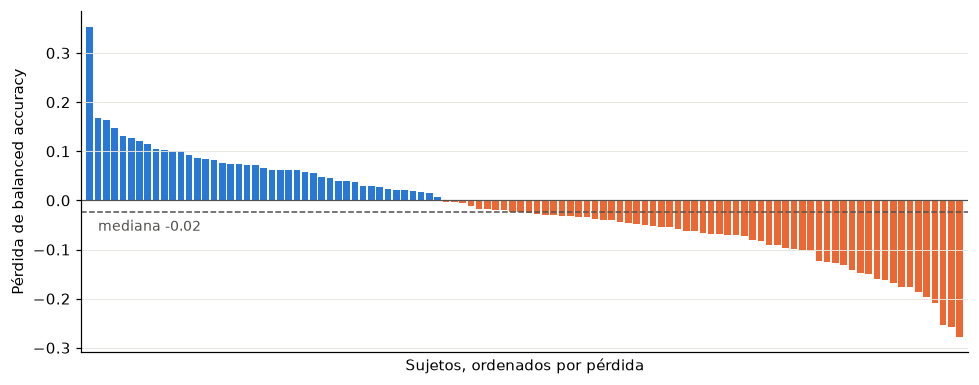

In [8]:
orden = comp.sort_values("perdida", ascending=False).reset_index(drop=True)
colores = np.where(orden["perdida"] > 0, AZUL, NARANJA)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(orden.index, orden["perdida"], width=0.8, color=colores)
ax.axhline(0, color=GRIS, lw=0.8)
ax.axhline(orden["perdida"].median(), color=GRIS, lw=1, ls="--")
ax.text(1, orden["perdida"].median() - 0.015, f"mediana {orden['perdida'].median():+.2f}",
        ha="left", va="top", color=GRIS, fontsize=9)
ax.set_xlim(-1, len(orden))
ax.set_xticks([])
ax.set_xlabel("Sujetos, ordenados por pérdida")
ax.set_ylabel("Pérdida de balanced accuracy")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(RESULTADOS / "02_perdida_por_sujeto.png", dpi=200)


## Control · solo canales motores

¿El resultado se debe a que CSP con 64 canales sobreajusta cuando cada sujeto tiene solo ~36 ensayos de entrenamiento? Se repite la comparación con los 21 canales sobre la corteza motora (filas FC, C y CP).

In [9]:
from bci.datos import cargar_raw
nombres = cargar_raw(1).copy().pick("eeg").ch_names
motores = [c for c in nombres if c.rstrip("z0123456789").upper() in ("FC", "C", "CP")]
idx = [nombres.index(c) for c in motores]
Xm = np.ascontiguousarray(X[:, idx, :])

intra_m = evaluar_intra(pipe, Xm, y, grupos, n_splits=5, n_repeats=10, semilla=0)
entre_m = evaluar_entre(pipe, Xm, y, grupos, n_jobs=6)
control = intra_m.merge(entre_m, on=["sujeto", "n_ensayos"], suffixes=("_intra", "_entre"))
control.to_csv(RESULTADOS / "02_control_canales_motores.csv", index=False)

print(f"{len(motores)} canales: {', '.join(motores)}")
for m in ["balanced_accuracy", "auc"]:
    p = wilcoxon(control[m + "_intra"], control[m + "_entre"]).pvalue
    print(f"{m:18s} dentro {control[m + '_intra'].mean():.3f} | entre {control[m + '_entre'].mean():.3f} | Wilcoxon p = {p:.2g}")


21 canales: FC5, FC3, FC1, FCz, FC2, FC4, FC6, C5, C3, C1, Cz, C2, C4, C6, CP5, CP3, CP1, CPz, CP2, CP4, CP6
balanced_accuracy  dentro 0.614 | entre 0.622 | Wilcoxon p = 0.37
auc                dentro 0.644 | entre 0.711 | Wilcoxon p = 3.1e-07


## Lectura de los resultados

**1. H1 no se sostiene en este dataset.** El modelo entrenado con otros 105 sujetos rinde igual o mejor que el entrenado con los datos de cada persona:

- Balanced accuracy media: 0,604 dentro del sujeto contra 0,623 entre sujetos. La diferencia no es significativa (Wilcoxon pareado, p = 0,069).
- AUC media: 0,633 dentro contra 0,709 entre, a favor del modelo entre sujetos (p = 3,9 × 10⁻⁹).
- Solo 43 de 106 sujetos pierden desempeño al usar el modelo de otros.
- El control con los 21 canales motores da lo mismo (balanced accuracy 0,614 contra 0,622, p = 0,37). No es un artefacto de usar 64 canales.

**2. La explicación más probable es la cantidad de datos.** Dentro del sujeto, cada modelo se entrena con unos 36 ensayos; entre sujetos, con unos 4.700. Con tan pocos ensayos, los filtros CSP de un sujeto se estiman mal, y un modelo general bien estimado compensa no estar personalizado. En datasets con más ensayos por sujeto se suele observar lo contrario; en el informe hay que presentarlo como propio de este escenario de pocos datos, no como una regla.

**3. El modelo entre sujetos ordena bien los ensayos, pero se equivoca de umbral.** Su AUC (0,709) es mucho mayor que su balanced accuracy (0,623); dentro del sujeto las dos están cerca (0,633 y 0,604). Una lectura posible es que el modelo general separa bien izquierda de derecha, pero su punto de corte no coincide con el de cada persona nueva. Si es así, unos pocos ensayos de calibración bastarían para corregirlo. Eso se pone a prueba en la etapa 5 (curva de calibración).

**4. Hay sujetos buenos y sujetos malos en los dos esquemas.** La correlación entre ambos es alta (Spearman 0,64), y solo 32 sujetos superan el azar dentro del sujeto y 37 entre sujetos, de 106. Coincide con lo que la literatura llama *BCI illiteracy*: una parte de las personas no produce un ERD que estos métodos detecten, con ningún esquema.

**Qué cambia para el trabajo.** La pregunta pasa de "¿cuánto se pierde?" a "¿qué conviene con pocos datos: un modelo personal o uno general?", y la etapa 5 gana peso: combinar el modelo general con unos pocos ensayos del sujeto nuevo podría superar a los dos.

**Limitaciones.** Con 45 ensayos por sujeto, cada estimación individual tiene mucho error (el umbral de azar es 0,644). El modelo general no hace ninguna adaptación al sujeto (por ejemplo, alinear sus covarianzas), algo que se puede probar en la etapa 4.